# Actividad — SVR para consumo energético de edificios
**Aprendizaje Supervisado · Sesión 6 · Regresión con máquinas de vectores de soporte**

**Qué haremos.** En la presentación vimos que SVR controla el error con un **tubo $\varepsilon$-insensible**
en vez de penalizar todos los residuos, y que el **truco del kernel** (lineal, polinomial, RBF) le permite
curvarse sin construir columnas nuevas a mano. Hoy aplicas todo eso a un problema real: predecir el
**consumo eléctrico diario (kWh)** de un edificio a partir del clima y sus características, donde la
relación con la temperatura **no es una línea recta** sino una curva en forma de U.

Trabaja **de forma individual**. Las celdas con `...` están incompletas: reemplaza los puntos suspensivos
con el código que falta (el comentario `✏️` te da una pista de qué se espera).

**Nombre:** Julian Emiliano Ortiz Rivero

## Parte 0 — Los datos

Cada fila es un edificio-día con 5 variables de entrada: `temperatura_c`, `superficie_m2`, `ocupantes`,
`aislamiento` (0 malo .. 1 excelente) y `fin_semana` (0/1). La salida es `consumo_kwh`. El consumo depende
de forma **no lineal** de la temperatura (sube con frío y con calor, mínimo cerca de los 21°C), y esa
curvatura se vuelve más suave cuanto mejor aislado está el edificio.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.metrics import mean_squared_error

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

datos = pd.read_csv("consumo-energetico.csv")
FEATS = ["temperatura_c", "superficie_m2", "ocupantes", "aislamiento", "fin_semana"]
X = datos[FEATS].values
y = datos["consumo_kwh"].values

Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42)
kf = KFold(5, shuffle=True, random_state=0)

def rmse(m, X, y):
    return np.sqrt(mean_squared_error(y, m.predict(X)))

print(f"n entrenamiento = {len(Xtr)}   n prueba = {len(Xte)}   variables = {FEATS}")
datos.describe().round(2).T

n entrenamiento = 675   n prueba = 225   variables = ['temperatura_c', 'superficie_m2', 'ocupantes', 'aislamiento', 'fin_semana']


,count,mean,std,min,25%,50%,75%,max
temperatura_c,900.0,18.57,12.79,-4.90,7.88,19.20,29.50,40.00
superficie_m2,900.0,145.19,51.96,48.00,107.90,137.45,173.42,420.00
ocupantes,900.0,4.45,2.31,1.00,2.00,4.00,6.00,8.00
aislamiento,900.0,0.50,0.21,0.04,0.33,0.52,0.67,0.98
fin_semana,900.0,0.50,0.50,0.00,0.00,0.00,1.00,1.00
consumo_kwh,900.0,29.23,11.19,8.03,20.76,27.22,36.33,75.05


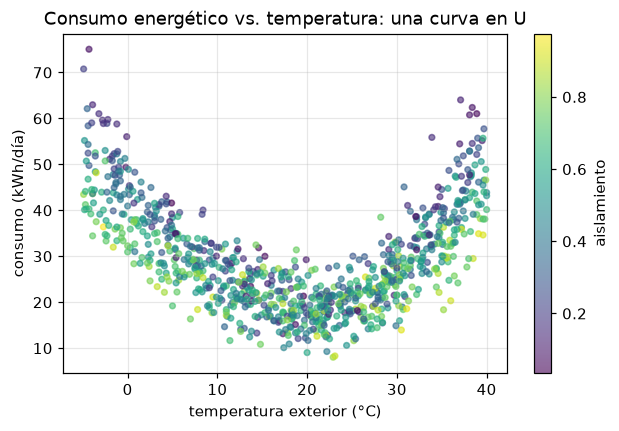

In [2]:
fig, ax = plt.subplots(figsize=(6.5, 4))
sca = ax.scatter(datos["temperatura_c"], datos["consumo_kwh"], c=datos["aislamiento"], cmap="viridis", s=14, alpha=0.6)
fig.colorbar(sca, ax=ax, label="aislamiento")
ax.set_xlabel("temperatura exterior (°C)"); ax.set_ylabel("consumo (kWh/día)")
ax.set_title("Consumo energético vs. temperatura: una curva en U");

**Respuesta:**

Una recta solo puede subir o bajar, mientras el consumo disminuye hasta una zona de confort y luego
vuelve a aumentar. En la gráfica, el consumo más bajo se concentra aproximadamente entre 18 °C y
24 °C.

## Parte 1 — SVR lineal como punto de partida  *(presentación A4, C1)*

Ajustamos un SVR con `kernel="linear"`. El escalador va dentro del `Pipeline` porque SVR usa distancias/productos
punto, y son sensibles a la escala de cada variable.

In [3]:
lineal = make_pipeline(
    StandardScaler(), SVR(kernel="linear", C=10, epsilon=1.0)
).fit(Xtr, ytr)
print(f"SVR lineal   RMSE entrenamiento = {rmse(lineal, Xtr, ytr):.2f}    RMSE prueba = {rmse(lineal, Xte, yte):.2f}")
print(f"Vectores de soporte: {lineal[-1].support_.shape[0]} de {len(Xtr)}")

SVR lineal   RMSE entrenamiento = 9.65    RMSE prueba = 11.54
Vectores de soporte: 619 de 675


**Respuesta:**

El RMSE de prueba es 11.54 kWh/día, casi igual a la desviación estándar de 11.19. Es alto para un
consumo medio de 29.23. El kernel lineal solo produce un hiperplano, por lo que no puede representar
el descenso y el aumento de la curva en U.

## Parte 2 — SVR con kernel RBF  *(presentación C1–C2)*

Repetimos con `kernel="rbf"` y los hiperparámetros **por defecto** de scikit-learn (sin ajustar nada todavía).

In [4]:
rbf_defecto = make_pipeline(StandardScaler(), SVR(kernel="rbf")).fit(Xtr, ytr)
print(f"SVR RBF (por defecto)  RMSE entrenamiento = {rmse(rbf_defecto, Xtr, ytr):.2f}    RMSE prueba = {rmse(rbf_defecto, Xte, yte):.2f}")
print(f"Hiperparámetros usados: C={rbf_defecto[-1].C}, epsilon={rbf_defecto[-1].epsilon}, gamma={rbf_defecto[-1].gamma}")
print(f"Vectores de soporte: {rbf_defecto[-1].support_.shape[0]} de {len(Xtr)}")

SVR RBF (por defecto)  RMSE entrenamiento = 5.63    RMSE prueba = 6.50
Hiperparámetros usados: C=1.0, epsilon=0.1, gamma=scale
Vectores de soporte: 658 de 675


**Respuesta:**

El RBF por defecto reduce el RMSE de prueba de 11.54 a 6.50 kWh/día. El resultado confirma que la
relación necesita curvatura y no puede resumirse con una sola recta.

## Parte 3 — Efecto de $C$ y de $\varepsilon$  *(presentación B4–B6)*

Primero variamos $C$ dejando $\varepsilon=1.0$ fijo; luego variamos $\varepsilon$ dejando $C=50$ fijo.
En ambos casos usamos kernel RBF con `gamma="scale"`.

      C  rmse_train  rmse_test  vectores_soporte
   0.01       10.94      12.04               620
   0.10        9.99      11.11               620
   1.00        5.68       6.61               542
  10.00        2.78       3.70               474
 100.00        1.93       3.05               479
1000.00        1.67       3.22               499


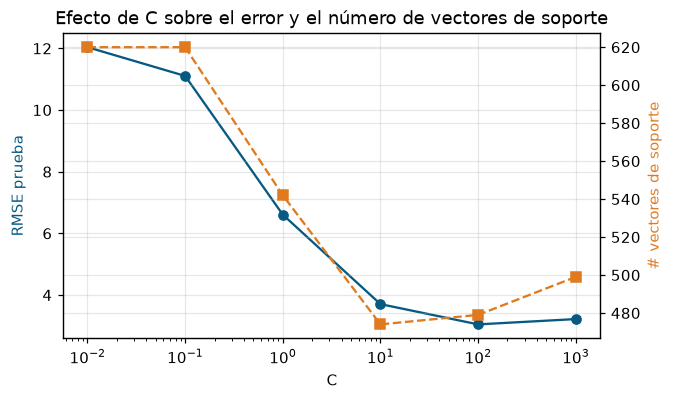

In [5]:
valores_C = [0.01, 0.1, 1, 10, 100, 1000]
filas_c = []
for C in valores_C:
    m = make_pipeline(
        StandardScaler(), SVR(kernel="rbf", C=C, epsilon=1.0)
    ).fit(Xtr, ytr)
    filas_c.append({"C": C, "rmse_train": rmse(m, Xtr, ytr), "rmse_test": rmse(m, Xte, yte),
                     "vectores_soporte": int(m[-1].support_.shape[0])})
tabla_c = pd.DataFrame(filas_c)
print(tabla_c.round(2).to_string(index=False))

fig, ax1 = plt.subplots(figsize=(6.3, 3.6))
ax1.plot(tabla_c["C"], tabla_c["rmse_test"], "o-", color="#065A82", label="RMSE prueba")
ax1.set_xscale("log"); ax1.set_xlabel("C"); ax1.set_ylabel("RMSE prueba", color="#065A82")
ax2 = ax1.twinx()
ax2.plot(tabla_c["C"], tabla_c["vectores_soporte"], "s--", color="#E07A1F", label="# vect. soporte")
ax2.set_ylabel("# vectores de soporte", color="#E07A1F")
ax1.set_title("Efecto de C sobre el error y el número de vectores de soporte");

In [6]:
valores_eps = [0.1, 0.5, 1, 2, 4, 8]
filas_e = []
for eps in valores_eps:
    m = make_pipeline(
        StandardScaler(), SVR(kernel="rbf", C=50, epsilon=eps)
    ).fit(Xtr, ytr)
    filas_e.append({"epsilon": eps, "rmse_train": rmse(m, Xtr, ytr), "rmse_test": rmse(m, Xte, yte),
                     "vectores_soporte": int(m[-1].support_.shape[0])})
tabla_e = pd.DataFrame(filas_e)
print(tabla_e.round(2).to_string(index=False))

 epsilon  rmse_train  rmse_test  vectores_soporte
     0.1        2.08       3.25               653
     0.5        2.04       3.17               578
     1.0        2.05       3.10               484
     2.0        2.16       3.14               306
     4.0        2.56       3.48               127
     8.0        3.98       5.11                51


**Respuesta:**

Con `C=0.01` el modelo subajusta y el RMSE de prueba es 12.04. El error baja hasta 3.05 con `C=100`,
pero sube a 3.22 con `C=1000`. Los vectores de soporte bajan en general al aumentar `C`, aunque no de
forma estricta en esta muestra. Al ampliar `epsilon` bajan de 653 a 51 porque más observaciones quedan
dentro del tubo sin penalización.

## Parte 4 — Comparación de kernels: lineal, polinomial y RBF  *(presentación C3–C4)*

Ahora comparamos los tres kernels **con el mismo protocolo**: mismo $C$, mismo $\varepsilon$, mismos
conjuntos de entrenamiento y prueba.

 kernel  rmse_train  rmse_test  vectores_soporte
 lineal        9.65      11.54               619
poly(3)        2.24       2.37               478
    rbf        2.05       3.10               484


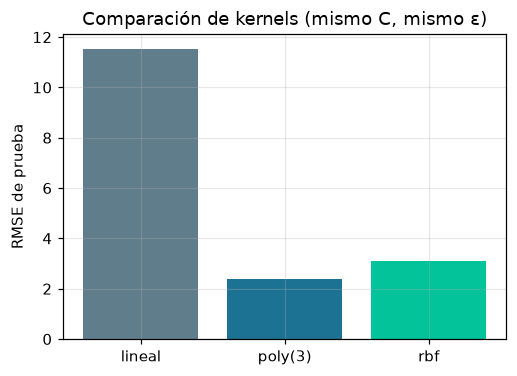

In [7]:
modelos4 = {
    "lineal": SVR(kernel="linear", C=50, epsilon=1.0),
    "poly(3)": SVR(kernel="poly", degree=3, coef0=1, C=50, epsilon=1.0),
    "rbf": SVR(kernel="rbf", C=50, epsilon=1.0),
}
filas4 = []
for nombre, svr in modelos4.items():
    m = make_pipeline(StandardScaler(), svr).fit(Xtr, ytr)
    filas4.append({"kernel": nombre, "rmse_train": rmse(m, Xtr, ytr), "rmse_test": rmse(m, Xte, yte),
                    "vectores_soporte": int(m[-1].support_.shape[0])})
tabla4 = pd.DataFrame(filas4)
print(tabla4.round(2).to_string(index=False))

fig, ax = plt.subplots(figsize=(5.2, 3.6))
ax.bar(tabla4["kernel"], tabla4["rmse_test"], color=["#607D8B", "#1C7293", "#02C39A"])
ax.set_ylabel("RMSE de prueba"); ax.set_title("Comparación de kernels (mismo C, mismo ε)");

**Respuesta:**

El kernel lineal obtiene el peor RMSE de prueba, 11.54, porque no sigue la curva en U. El polinomial
de grado 3 logra 2.37 y RBF 3.10. Ambos mejoran mucho al lineal, aunque el polinomial queda arriba y
usa un poco menos vectores de soporte: 478 frente a 484.

## Parte 5 — Ajuste de $C$, $\varepsilon$ y $\gamma$ con `GridSearchCV`  *(presentación D1–D2)*

Buscamos los tres hiperparámetros del kernel RBF **juntos**, con validación cruzada de 5 particiones.
La rejilla es moderada para que la celda no tarde demasiado; en un proyecto real valdría la pena
una rejilla más fina alrededor del óptimo encontrado aquí.

In [8]:
pipe_rbf = make_pipeline(StandardScaler(), SVR(kernel="rbf"))
malla = {"svr__C": np.logspace(0, 3, 6), "svr__gamma": np.logspace(-2, 1, 6), "svr__epsilon": [0.5, 1.0, 2.0]}
bus = GridSearchCV(
    pipe_rbf, malla, cv=kf, scoring="neg_root_mean_squared_error", n_jobs=1
)
bus.fit(Xtr, ytr)
print("Mejores hiperparámetros:", bus.best_params_)
print(f"RMSE de validación = {-bus.best_score_:.2f}    RMSE de prueba = {rmse(bus, Xte, yte):.2f}")
print(f"Vectores de soporte: {bus.best_estimator_[-1].support_.shape[0]} de {len(Xtr)}")

Mejores hiperparámetros: {'svr__C': np.float64(1000.0), 'svr__epsilon': 1.0, 'svr__gamma': np.float64(0.039810717055349734)}
RMSE de validación = 2.55    RMSE de prueba = 2.52
Vectores de soporte: 468 de 675


**Respuesta:**

La búsqueda eligió `C=1000`, `gamma=0.03981` y `epsilon=1`. El RMSE de prueba baja de 6.50 a 2.52
frente al RBF por defecto. Refinaría la rejilla alrededor de esos valores, con más puntos entre
`gamma=0.02` y `0.08`, además de valores de `C` cercanos a 1000, usando la misma validación cruzada.

## Parte 6 — Comparación final contra los modelos de sesiones anteriores  *(presentación E2)*

Ponemos el mejor SVR (de la Parte 5) a competir contra **OLS**, **Ridge** y **Lasso** (con validación
cruzada para su hiperparámetro), todos evaluados en el **mismo** conjunto de prueba.

In [9]:
modelos6 = {
    "OLS": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 50), cv=kf)),
    "Lasso": make_pipeline(
        StandardScaler(), LassoCV(alphas=np.logspace(-3, 2, 60), cv=kf, max_iter=100000)
    ),
    "SVR lineal": make_pipeline(StandardScaler(), SVR(kernel="linear", C=50, epsilon=1.0)),
    "SVR RBF (GridSearchCV)": bus.best_estimator_,
}
filas6 = []
for nombre, m in modelos6.items():
    if nombre != "SVR RBF (GridSearchCV)":
        m.fit(Xtr, ytr)
    filas6.append({"modelo": nombre, "rmse_prueba": round(rmse(m, Xte, yte), 3)})
comparacion = pd.DataFrame(filas6).sort_values("rmse_prueba").reset_index(drop=True)
print(comparacion.to_string(index=False))

comentarios = {
    "SVR RBF (GridSearchCV)": "Captura la relación no lineal y obtiene el menor error.",
    "SVR lineal": "No representa la curva en U de la temperatura.",
    "OLS": "Sirve como referencia lineal, pero no capta la curvatura.",
    "Ridge": "Regulariza los coeficientes sin añadir relaciones no lineales.",
    "Lasso": "Selecciona variables, aunque conserva una forma lineal.",
}
entregable = comparacion.copy()
entregable["comentario"] = entregable["modelo"].map(comentarios)
entregable.to_csv("entregable-unidad-06.csv", index=False)
entregable

                modelo  rmse_prueba
SVR RBF (GridSearchCV)        2.517
                 Ridge       11.132
                 Lasso       11.155
                   OLS       11.155
            SVR lineal       11.542


,modelo,rmse_prueba,comentario
0,SVR RBF (GridSearchCV),2.517,Captura la relación no lineal y obtiene el men...
1,Ridge,11.132,Regulariza los coeficientes sin añadir relacio...
2,Lasso,11.155,"Selecciona variables, aunque conserva una form..."
3,OLS,11.155,"Sirve como referencia lineal, pero no capta la..."
4,SVR lineal,11.542,No representa la curva en U de la temperatura.


**Respuesta:**

El orden es SVR RBF, Ridge, Lasso, OLS y SVR lineal. El SVR mejora en 8.62 kWh/día al mejor modelo
lineal, Ridge. Ridge y Lasso regularizan coeficientes, pero no crean la curvatura necesaria. Para
confiar más en la diferencia repetiría la comparación con validación cruzada anidada o con varias
particiones de prueba.

## Parte 7 — Interpretación: ¿qué aprendió el modelo sobre la temperatura?

Fijamos todas las variables en su **mediana** y vamos moviendo solo `temperatura_c`, para ver qué
predice cada modelo a lo largo del rango de temperaturas. Esto se llama una curva de **dependencia parcial**
simple.

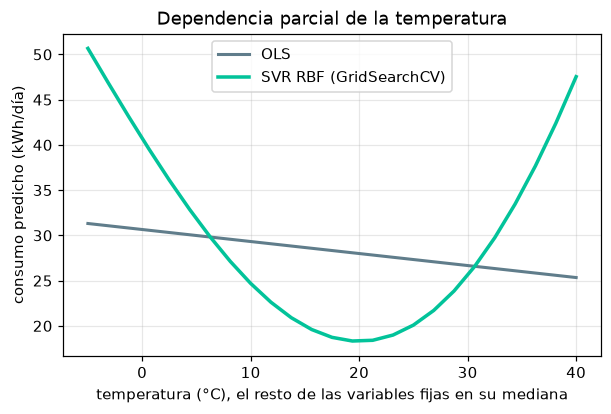

In [10]:
mediana = datos[FEATS].median()
rejilla_temp = np.linspace(-5, 40, 25)
filas7 = []
for t in rejilla_temp:
    fila = mediana.copy()
    fila["temperatura_c"] = t
    xf = fila[FEATS].values.reshape(1, -1)
    filas7.append({"temperatura": t,
                    "OLS": modelos6["OLS"].predict(xf)[0],
                    "SVR_RBF": modelos6["SVR RBF (GridSearchCV)"].predict(xf)[0]})
dep = pd.DataFrame(filas7)

fig, ax = plt.subplots(figsize=(6.3, 3.8))
ax.plot(dep["temperatura"], dep["OLS"], color="#607D8B", lw=2, label="OLS")
ax.plot(dep["temperatura"], dep["SVR_RBF"], color="#02C39A", lw=2.3, label="SVR RBF (GridSearchCV)")
ax.set_xlabel("temperatura (°C), el resto de las variables fijas en su mediana")
ax.set_ylabel("consumo predicho (kWh/día)")
ax.set_title("Dependencia parcial de la temperatura")
ax.legend();

**Respuesta:**

OLS produce una línea y no muestra una temperatura de confort. El SVR RBF sí forma un mínimo cerca de
21 °C. Esta diferencia permite ubicar una zona razonable de operación antes de encender calefacción
o aire acondicionado, sin interpretar una tendencia lineal que no existe.

**Respuesta:**

Usaría SVR con kernel RBF porque puede representar relaciones curvas como la temperatura y el consumo.
Estandarizaría las variables dentro del pipeline para que ninguna escala domine las distancias.
Ajustaría `C`, `epsilon` y `gamma` juntos mediante validación cruzada.
En datos como estos esperaría un RMSE menor que el de un modelo lineal.
Reservaría el conjunto de prueba para una sola evaluación final.
También revisaría el costo de cómputo y la menor facilidad de interpretación de SVR.
Si el conjunto creciera mucho, compararía alternativas más rápidas antes de ampliar la búsqueda.

---
**Reto opcional — ¿importa estandarizar en SVR?** Comparamos el kernel RBF **con** y **sin** `StandardScaler`,
manteniendo los mismos $C$ y $\varepsilon$. Recuerda: RBF depende de distancias $\lVert x - x'\rVert$, y
nuestras variables tienen escalas muy distintas (`temperatura_c` en decenas, `aislamiento` entre 0 y 1).

In [11]:
con_escalado = make_pipeline(StandardScaler(), SVR(kernel="rbf", C=50, epsilon=1.0)).fit(Xtr, ytr)
sin_escalado = SVR(kernel="rbf", C=50, epsilon=1.0).fit(Xtr, ytr)
for nombre, m in [("con StandardScaler", con_escalado), ("sin escalar", sin_escalado)]:
    nsv = m[-1].support_.shape[0] if hasattr(m, "steps") else m.support_.shape[0]
    print(f"{nombre:22s} RMSE prueba = {rmse(m, Xte, yte):.2f}   vectores de soporte = {nsv}")

con StandardScaler     RMSE prueba = 3.10   vectores de soporte = 484
sin escalar            RMSE prueba = 9.19   vectores de soporte = 596


**Respuesta:**

Sin escalado, el RMSE de prueba aumenta de 3.10 a 9.19. `superficie_m2` domina las distancias porque
sus valores son mucho mayores que los de `aislamiento`, `fin_semana` y las demás variables.